In [1]:
# Necessary imports #

# General #

import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, ExpSineSquared,
    DotProduct, ConstantKernel as C
)
import sys
import os

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(repo_root)

# Cloelib #

from cloelib.cosmology.camb_cosmology import CAMBBackground, CAMBLinearPerturbations, CAMBNonLinearPerturbations
from cloelib.cosmology.HMcode2020Emu_cosmology import HMemuLinearPerturbations, HMemuNonLinearPerturbations
from cloelib.observables.photo import ShearTracer, PositionsTracer
from cloelib.summary_statistics.angular_two_point import AngularTwoPoint
from cloelib.summary_statistics.angular_correlation_function_wigner import AngularCorrelationFunctionWigner
import euclidlib as el
import seaborn as sns

# Gaussian processes #

from binz.run_gp import build_gp_nz 



2026-03-11 14:34:44.377704: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


/home/jipdebuck/miniconda3/envs/venv_310/lib/python3.10/site-packages/HMcode2020Emu
Loading linear emulator...


2026-03-11 14:34:46.335631: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Linear emulator loaded in memory.
Loading nonlinear emulator...
Non-linear emulator loaded in memory.
Loading linear emulator...
Baryonic boost emulator loaded in memory.
Loading sigma8 emulator...
Linear emulator loaded in memory.


## Preparing and plotting the original $n(z)$ from the Euclid overview

In [2]:
# Import and prepare original n(z) distribution #

zs = np.linspace(1e-4, 3, 100)
z, nz = el.phz.redshift_distributions('/home/jipdebuck/nzTabSPV3.fits')

def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)

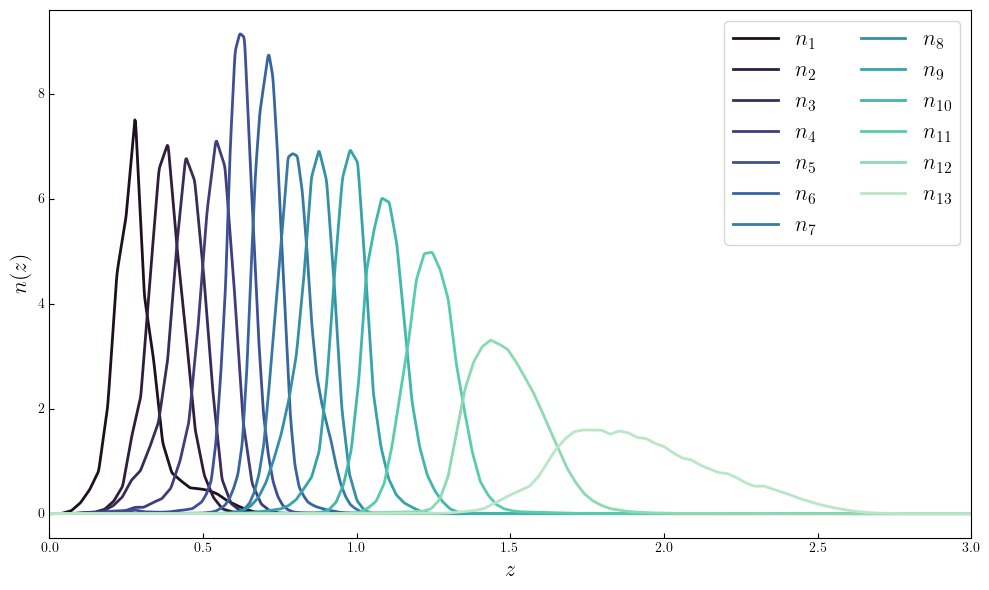

In [11]:
# Plotting of original n(z) distributions #

fig, axs = plt.subplots(figsize=(10, 6))

# Customize tick parameters for both axes
axs.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
#for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
#    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs.plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
#axs[0].set_xlabel(r'$z$')
#axs[0].set_ylabel(r'Positions $n(z)$')
#axs[0].set_xlim(0, 4)
#xs[0].legend(frameon=False, ncol=2)

axs.set_xlabel(r'$z$', fontsize=16)
axs.set_ylabel(r'$n(z)$', fontsize=16)
axs.set_xlim(0, 3)
axs.legend(frameon=True, ncol=2, fontsize=16)

plt.tight_layout()
plt.savefig('/home/jipdebuck/plots/nz_DR3.png', dpi=600, bbox_inches='tight')


## Reconstruct $n(z)$ using Gaussian processes

In [17]:
# Function for plotting old and new n(z) #

def plot_nz_old_new(new_nz, new_z, X_nodes, y_nodes, palette, ax, old_nz=None, old_z=None, original=True, use_palette=True, color='black'):
    # Plot GP reconstruction results #
    for j, nz in enumerate(n_meds):
        y_pred, y_std = new_nz[j]
        X_train, y_train = X_nodes[j], y_nodes[j]
        if use_palette:
            colors = palette
        else:
            colors = [color]*len(new_nz)
        ax.plot(new_z, y_pred, color=colors[j], label=f"$n_{{{j+1}}}$ reconstruction")
        #ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
         #           color=palette[j], alpha=0.2)
        ax.scatter(X_train, y_train, color=colors[j], edgecolor='black', s=80, zorder=3, label=f"Node {j+1}")
        if original and old_nz is not None and old_z is not None:
            ax.plot(old_z, old_nz[j+1], '--', color=colors[j], alpha=0.4)
    ax.set_xlabel(r"$z$", fontsize=16)
    ax.set_ylabel(r"$n(z)$", fontsize=16)
    ax.set_xlim(0, 3)
#    ax.legend(loc="upper right", ncol=2)
    plt.savefig('/home/jipdebuck/plots/nz_old_new.png', dpi=600, bbox_inches='tight')


In [13]:
# Define parameters for GP reconstruction #

z_meds = []   # positions of median redshift for each bin
n_meds = []   # height of n(z) at median redshift for each bin

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]
    z_meds.append(z_med)
    n_meds.append(n_med)

corr_len = 0.03                                # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = Matern
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude

print(z_meds)


[0.27590319200705216, 0.37661359871457145, 0.44582911661616964, 0.5424196600268599, 0.6214748503007049, 0.7093980587467854, 0.7985657466455814, 0.8666609162525956, 0.9779689861106543, 1.0913635344559958, 1.2432247853949816, 1.4793166612176567, 1.892923608652228]


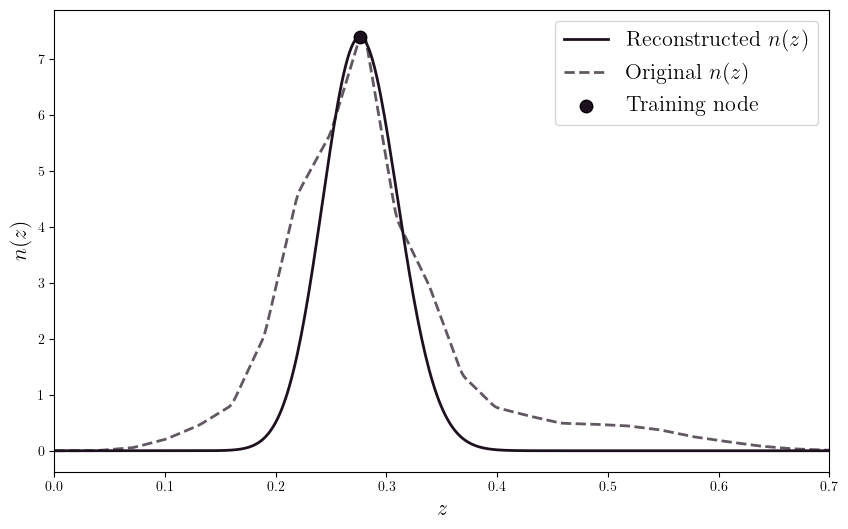

In [79]:
priors_1, predictions_1 = build_gp_nz([n_meds[0]], [z_meds[0]], 0.05, (0, 0.7), np.linspace(0, 0.7, 400), alpha, RBF, nu, const_value, const_bounds)
fig, ax = plt.subplots(figsize=(10,6))
y_pred, y_std = predictions_1[0]
X_train, y_train = z_meds[0], n_meds[0]
colors = palette
ax.plot(np.linspace(0, 0.7, 400), y_pred, color=colors[0], lw=2, label=f"Reconstructed $n(z)$")
#ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
#                    color=palette[j], alpha=0.2)
ax.plot(z, dndz_she_norm[1], '--', color=colors[0], alpha=0.7, lw=2, label="Original $n(z)$")
ax.scatter(X_train, y_train, color=colors[0], edgecolor='black', s=80, zorder=3, label=f"Training node")
ax.set_xlabel(r"$z$", fontsize=16)
ax.set_ylabel(r"$n(z)$", fontsize=16)
ax.set_xlim(0, 0.7)
ax.legend(loc="upper right", fontsize=16)
plt.savefig('/home/jipdebuck/plots/GP_example.pdf', bbox_inches='tight')

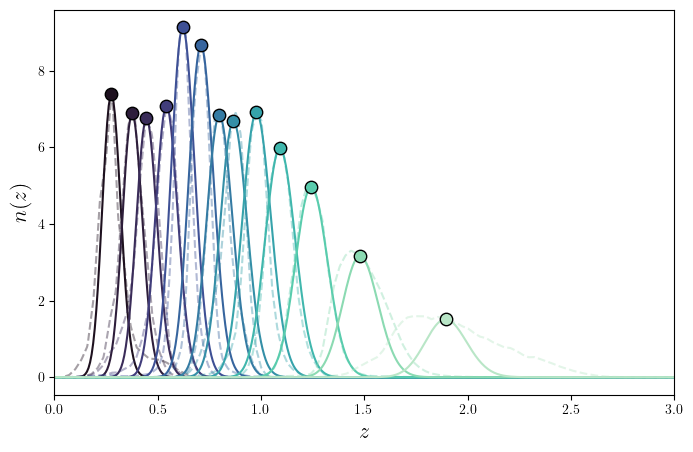

In [21]:
# GP reconstruction and plotting of results #

fig, ax = plt.subplots(figsize=[8, 5])
# Perform GP reconstruction #
priors, predictions = build_gp_nz(n_meds, z_meds, 0.025, z_bounds, z_pred, alpha, RBF, nu, const_value, const_bounds)

# Plot GP reconstruction results #
palette = sns.color_palette("mako", 13)
plot_nz_old_new(predictions, z_pred, z_meds, n_meds, palette, ax, old_nz=dndz_she_norm, old_z=z)


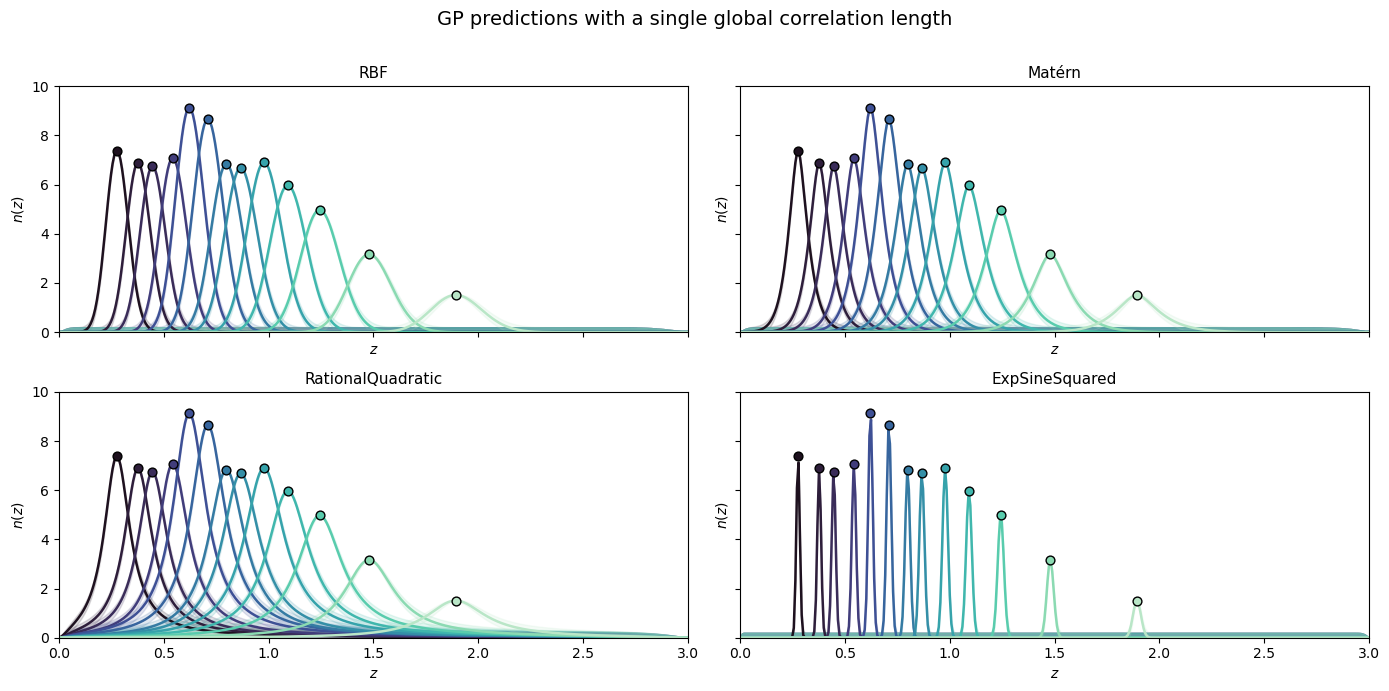

In [21]:
# Results using different kernels #

# Define different kernels #
kernel_dict = {
    "RBF": RBF,
    "Matérn": Matern,
    "RationalQuadratic": RationalQuadratic,
    "ExpSineSquared": ExpSineSquared
}

# Initialize figure for plotting #
n_kernels = len(kernel_dict)
palette = sns.color_palette("mako", len(dndz_she_norm))

fig, axs = plt.subplots(nrows=int(np.ceil(n_kernels/2)), ncols=2,
                        figsize=(14, 3.5 * int(np.ceil(n_kernels/2))),
                        sharex=True, sharey=True)
axs = axs.flatten()

# Compute and plot GP predictions for each kernel #
for ax, (kname, kernel) in zip(axs, kernel_dict.items()):
    
    z_meds = []
    n_meds = []
    for j, (key, nz) in enumerate(dndz_she_norm.items()):
        # --- Compute CDF and median node ---
        cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
        cdf /= cdf[-1]
        z_med = np.interp(0.5, cdf, z)
        n_med = nz[np.argmin(np.abs(z - z_med))]
        z_meds.append(z_med)
        n_meds.append(n_med)

    
    gp_prior, gp_pred = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel, nu, const_value, const_bounds)

    for j, nz in enumerate(n_meds):
        y_pred, y_std = gp_pred[j]
        ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} mean", lw=1.8)
        ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(),
                        (y_pred + y_std).ravel(), color=palette[j], alpha=0.15)
        ax.scatter(z_meds[j], nz, color=palette[j], edgecolor='black', s=40, zorder=3)

        ax.set_title(kname, fontsize=11)
        ax.set_xlim(0, 3)
        ax.set_ylim(0,10)
        ax.set_xlabel(r"$z$")
        ax.set_ylabel(r"$n(z)$")

for ax in axs[len(kernel_dict):]:
    ax.axis("off")

fig.suptitle("GP predictions with a single global correlation length", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


## Compute $C_{\ell}$'s using the reconstructed $n(z)$

In [3]:
# Compute the C_ell's using the original n(z) #

# The arguments of the Background functions follow the cosmology.API
background = CAMBBackground(H0=70.0, 
                            Omega_cdm0=0.25, 
                            Omega_b0=0.05, 
                            w0=-1, 
                            wa=0, 
                            Omega_k0 = 0.0, 
                            ns = 0.96, 
                            As = 2e-9,
                            mnu = 0.06,
                            gamma_MG = 0.545,
                            N_mnu = 1)
linear_perturbations_emu = HMemuLinearPerturbations(background, zs)
nonlinear_perturbations_emu = HMemuNonLinearPerturbations(background, linear_perturbations_emu, zs, log10TAGN=7.8)

# Select the perturbations object you want to use
perturbations = nonlinear_perturbations_emu

# Define the tracers
tracer_pos = PositionsTracer(perturbations=perturbations, 
                             dndz=my_dndz_pos_norm,
                             z = zs,
                             galaxy_bias_model='poly',
                             nuisance_params={'b1_photo_poly0': 1.0, 'b1_photo_poly1': 0.0, 
                                              'b1_photo_poly2': 0.0, 'b1_photo_poly3': 0.0,
                                              'magnification_bias_1': 0.0, 'magnification_bias_2': 0.0,
                                              'magnification_bias_3': 0.0, 'magnification_bias_4': 0.0,
                                              'magnification_bias_5': 0.0, 'magnification_bias_6': 0.0,
                                              'magnification_bias_7': 0.0, 'magnification_bias_8': 0.0,
                                              'magnification_bias_9': 0.0, 'magnification_bias_10': 0.0,
                                              'magnification_bias_11': 0.0, 'magnification_bias_12': 0.0,
                                              'magnification_bias_13': 0.0,
                                              'dz_pos_1': 0.0001, 'dz_pos_2': 0.0001,
                                              'dz_pos_3': 0.0001, 'dz_pos_4': 0.0001,
                                              'dz_pos_5': 0.0001, 'dz_pos_6': 0.0001,
                                              'dz_pos_7': 0.0001, 'dz_pos_8': 0.0001,
                                              'dz_pos_9': 0.0001, 'dz_pos_10': 0.0001,
                                              'dz_pos_11': 0.0001, 'dz_pos_12': 0.0001,
                                              'dz_pos_13': 0.0001})

tracer_she = ShearTracer(perturbations=perturbations, 
                             dndz=my_dndz_she_norm,
                             z = zs,
                             nuisance_params={'AIA': 1.72, 'CIA': 0.0134, 'EtaIA':-0.41,
                                              'multiplicative_bias_1': 0.001, 'multiplicative_bias_2': 0.001,
                                              'multiplicative_bias_3': 0.001, 'multiplicative_bias_4': 0.001,
                                              'multiplicative_bias_5': 0.001, 'multiplicative_bias_6': 0.001,
                                              'multiplicative_bias_7': 0.001, 'multiplicative_bias_8': 0.001,
                                              'multiplicative_bias_9': 0.001, 'multiplicative_bias_10': 0.001,
                                              'multiplicative_bias_11': 0.001, 'multiplicative_bias_12': 0.001,
                                              'multiplicative_bias_13': 0.001,
                                              'dz_shear_1': 0.0001, 'dz_shear_2': 0.0001,
                                              'dz_shear_3': 0.0001, 'dz_shear_4': 0.0001,
                                              'dz_shear_5': 0.0001, 'dz_shear_6': 0.0001,
                                              'dz_shear_7': 0.0001, 'dz_shear_8': 0.0001,
                                              'dz_shear_9': 0.0001, 'dz_shear_10': 0.0001,
                                              'dz_shear_11': 0.0001, 'dz_shear_12': 0.0001,
                                              'dz_shear_13': 0.0001})

In [4]:
# Resampling reconstructed n(z) #

z_pred_res = z_pred.reshape(-1, 1)
def resample_dndz_gp(gp_predictions, z_pred, zs):
    for key in gp_predictions.keys():
        gp_predictions[key] = gp_predictions[key][0]

    my_dndz = np.vstack(list(gp_predictions.values())) 
    my_dndz_norm = np.zeros([len(gp_predictions), len(zs)])
    for i in range(len(gp_predictions)):
        # gp_predictions[i][0] is 1D array of n(z) for bin i

        my_dndz_norm[i, :] = np.interp(zs, z_pred[:,0], my_dndz[i, :])
    
    return my_dndz_norm

my_dndz_norm_gp = resample_dndz_gp(predictions, z_pred_res, zs)



NameError: name 'z_pred' is not defined

In [24]:
# Compute the C_ell's using the reconstructed n(z) #

tracer_pos_gp = PositionsTracer(perturbations=perturbations, 
                             dndz=my_dndz_norm_gp,  
                             z = zs,
                             galaxy_bias_model='poly',
                             nuisance_params={'b1_photo_poly0': 1.0, 'b1_photo_poly1': 0.0, 
                                              'b1_photo_poly2': 0.0, 'b1_photo_poly3': 0.0,
                                              'magnification_bias_1': 0.0, 'magnification_bias_2': 0.0,
                                              'magnification_bias_3': 0.0, 'magnification_bias_4': 0.0,
                                              'magnification_bias_5': 0.0, 'magnification_bias_6': 0.0,
                                              'magnification_bias_7': 0.0, 'magnification_bias_8': 0.0,
                                              'magnification_bias_9': 0.0, 'magnification_bias_10': 0.0,
                                              'magnification_bias_11': 0.0, 'magnification_bias_12': 0.0,
                                              'magnification_bias_13': 0.0,
                                              'dz_pos_1': 0.0001, 'dz_pos_2': 0.0001,
                                              'dz_pos_3': 0.0001, 'dz_pos_4': 0.0001,
                                              'dz_pos_5': 0.0001, 'dz_pos_6': 0.0001,
                                              'dz_pos_7': 0.0001, 'dz_pos_8': 0.0001,
                                              'dz_pos_9': 0.0001, 'dz_pos_10': 0.0001,
                                              'dz_pos_11': 0.0001, 'dz_pos_12': 0.0001,
                                              'dz_pos_13': 0.0001})

tracer_she_gp = ShearTracer(perturbations=perturbations, 
                             dndz=my_dndz_norm_gp,
                             z = zs,
                             nuisance_params={'AIA': 1.72, 'CIA': 0.0134, 'EtaIA':-0.41,
                                              'multiplicative_bias_1': 0.001, 'multiplicative_bias_2': 0.001,
                                              'multiplicative_bias_3': 0.001, 'multiplicative_bias_4': 0.001,
                                              'multiplicative_bias_5': 0.001, 'multiplicative_bias_6': 0.001,
                                              'multiplicative_bias_7': 0.001, 'multiplicative_bias_8': 0.001,
                                              'multiplicative_bias_9': 0.001, 'multiplicative_bias_10': 0.001,
                                              'multiplicative_bias_11': 0.001, 'multiplicative_bias_12': 0.001,
                                              'multiplicative_bias_13': 0.001,
                                              'dz_shear_1': 0.0001, 'dz_shear_2': 0.0001,
                                              'dz_shear_3': 0.0001, 'dz_shear_4': 0.0001,
                                              'dz_shear_5': 0.0001, 'dz_shear_6': 0.0001,
                                              'dz_shear_7': 0.0001, 'dz_shear_8': 0.0001,
                                              'dz_shear_9': 0.0001, 'dz_shear_10': 0.0001,
                                              'dz_shear_11': 0.0001, 'dz_shear_12': 0.0001,
                                              'dz_shear_13': 0.0001})



## Plot and compare window functions

In [9]:
import matplotlib as mpl 
mpl.rcParams['font.family'] = "serif"
mpl.rcParams['font.serif'] = "Times New Roman"
mpl.rcParams['text.usetex'] = True

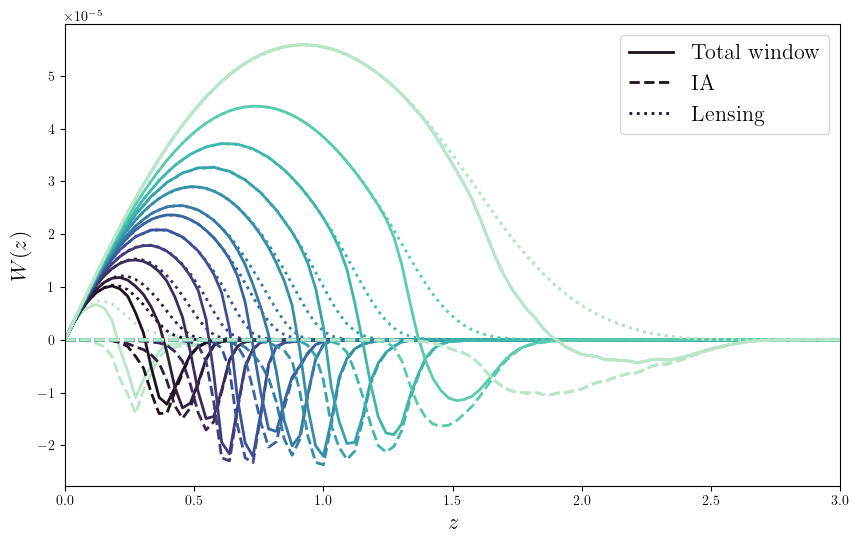

In [32]:
colors = sns.color_palette("mako", 13)

plt.figure(figsize=(10, 6))

#plt.subplot(1,2,1)

for i in range(0, 14):
    # Plot the window
    plt.plot(perturbations.z, 
             tracer_she.get_window(perturbations.z)[i, :], 
             linewidth=2, 
             color=colors[i-1], 
             label=f'Total window' if i == 1 else "")
    
    # Plot the intrinsic alignment window
    plt.plot(perturbations.z, 
             tracer_she.get_window_IA(perturbations.z)[i, :], 
             linewidth=2, 
             linestyle='--', 
             color=colors[i-1], 
             label=f'IA' if i == 1 else "")
    
    # Plot the lensing window
    plt.plot(perturbations.z, 
             tracer_she.get_window_lensing(perturbations.z)[i, :], 
             linewidth=2, 
             linestyle=':', 
             color=colors[i-1], 
             label=f'Lensing' if i == 1 else "")

# Label the axes
plt.xlabel(r'$z$', fontsize=16)
plt.ylabel(r'$W(z)$', fontsize=16)
plt.xlim(0,3)
plt.legend(fontsize=16, loc='upper right')
plt.savefig('/home/jipdebuck/plots/window_WL.pdf', bbox_inches='tight')

# Add the legend and grid

#plt.grid(True)

#plt.subplot(1,2,2)

#for i in range(0, 14):
    # Plot the window
#    plt.plot(perturbations.z, 
#             tracer_she_gp.get_window(perturbations.z)[i, :], 
#             linewidth=2, 
#             color=colors[i-1], 
#             label=f'Total window (reconstructed)' if i == 1 else "")
    
    # Plot the intrinsic alignment window
#    plt.plot(perturbations.z, 
 #            tracer_she_gp.get_window_IA(perturbations.z)[i, :], 
 #            linewidth=2, 
 #            linestyle='--', 
 #            color=colors[i-1], 
 #            label=f'IA (reconstructed)' if i == 1 else "")
    
    # Plot the lensing window
 #   plt.plot(perturbations.z, 
 #            tracer_she_gp.get_window_lensing(perturbations.z)[i, :], 
 #            linewidth=2, 
 #            linestyle=':', 
 #            color=colors[i-1], 
 #            label=f'Lensing (reconstructed)' if i == 1 else "")

# Label the axes
#plt.xlabel(r'$z$')
#plt.ylabel(r'$W(z)$')

# Add the legend and grid
#plt.legend(fontsize=12, loc='upper right')
#plt.grid(True)


# Show the plot
#plt.show()


## Plot and compare $C_{\ell}$'s computed using original and reconstructed $n(z)$

In [5]:
# Compute angular two-point statistics #

nl = 100
ells = np.logspace(1., np.log10(3000), nl)

twopoint_pospos = AngularTwoPoint(tracer_pos, tracer_pos)
twopoint_shepos = AngularTwoPoint(tracer_she, tracer_pos)
twopoint_posshe = AngularTwoPoint(tracer_pos, tracer_she)
twopoint_sheshe = AngularTwoPoint(tracer_she, tracer_she)

cells ={**twopoint_pospos.get_Cl(ells, 0, perturbations.k)
, **twopoint_shepos.get_Cl(ells, 0, perturbations.k)
, **twopoint_sheshe.get_Cl(ells, 0, perturbations.k)}

twopoint_pospos_gp = AngularTwoPoint(tracer_pos_gp, tracer_pos_gp)
twopoint_shepos_gp = AngularTwoPoint(tracer_she_gp, tracer_pos_gp)
twopoint_posshe_gp = AngularTwoPoint(tracer_pos_gp, tracer_she_gp)
twopoint_sheshe_gp = AngularTwoPoint(tracer_she_gp, tracer_she_gp)

cells_gp ={**twopoint_pospos_gp.get_Cl(ells, 0, perturbations.k)
, **twopoint_shepos_gp.get_Cl(ells, 0, perturbations.k)
, **twopoint_sheshe_gp.get_Cl(ells, 0, perturbations.k)}

NameError: name 'tracer_pos_gp' is not defined

In [35]:
# Function for plotting old and new C_ell's #

from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, BoundaryNorm

def plot_cls_old_new(n_bins, old_cells, new_cells, probe_1, probe_2):
    n_bins = n_bins
    cmap_pos = plt.cm.Oranges_r        
    fig, axes = plt.subplots(3, 5, figsize=(14.5,9), sharex=True)
    axes_to_remove = [axes[2,3], axes[2,4]]
    for ax in axes_to_remove:
        ax.remove()
    max_offset = n_bins - 1  
    for i in range(1, n_bins + 1):
        for j in range(i, n_bins + 1):
            ax = axes[(i - 1) // 5, (i - 1) % 5]
            offset = j - i
            cell_diff = 100*(np.asarray(old_cells[probe_1, probe_2,i, j][0, 0]) - np.asarray(new_cells[probe_1, probe_2,i, j][0, 0])) / (np.asarray(cells[probe_1, probe_2,i, j][0, 0]))
            ell = cells[probe_1,probe_2,i,j].ell
            if offset > 0:
                color = cmap_pos(offset / max_offset)
            else:
                color = 'black'  # self-correlation
            ax.plot(ell, cell_diff, color=color, lw=1.5)
        ax.set_xscale("log")
        ax.set_xlim(10, 1500)
        if i==1:
            ax.set_ylim(-10000, 1000)
        else:
            ax.set_ylim(-15,10)
        ax.set_title(f'Bin {i}', fontsize=10)
        ax.tick_params(axis='both', labelsize=8)
    line_offsets = np.arange(1, n_bins+1)
    line_colors = [cmap_pos(offset / max_offset) for offset in line_offsets]
    colors = [(0,0,0)] + line_colors
    cmap = ListedColormap(colors)
    bounds = np.arange(0, n_bins+1)  
    norm = BoundaryNorm(bounds, cmap.N)
    cbar_ax = fig.add_axes([0.6, 0.15, 0.3, 0.03])
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Offset', fontsize=10)
    fig.supxlabel("angular mode $\\ell$", y=-0.05, va="top")
    fig.supylabel(r'$\Delta C^{\rm EE}(\ell)/C^{\rm EE}(\ell)\cdot 100$', x=-0.1, ha="right")
    fig.subplots_adjust(
    left=-0.05,    # space on the left for y-axis
    right=0.95,   # space on the right
    top=0.92,     # space at the top
    bottom=0,  # space at the bottom for x-axis + colorbar
    hspace=0.3,   # vertical spacing between subplots
    wspace=0.25   # horizontal spacing between subplots
    )
    plt.show()
    

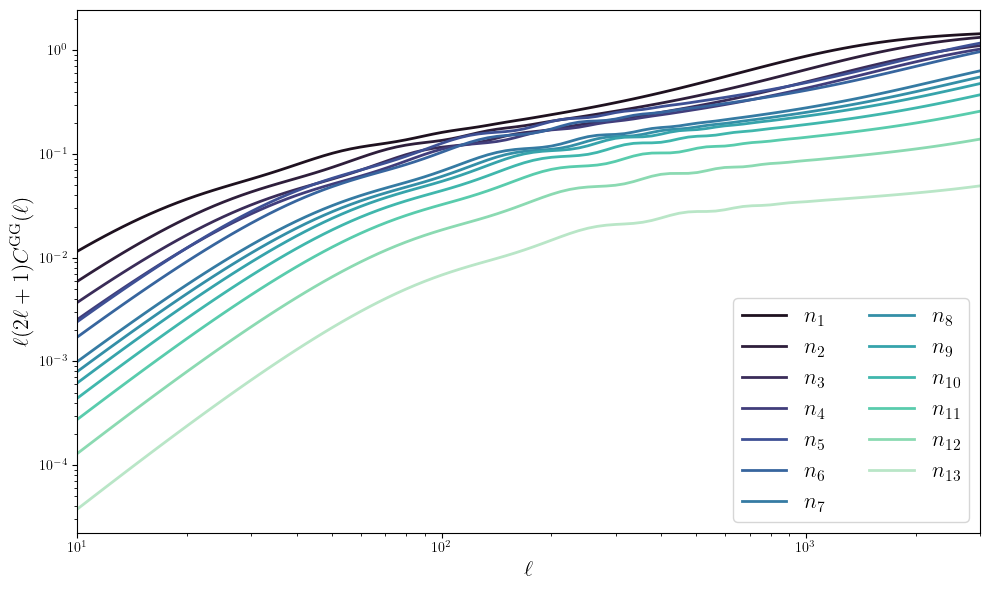

In [48]:
# Plot POS-POS C_ell's comparison #

fig, axes = plt.subplots(figsize=(10, 6))

##for i in range(0, 13):
 #   ells = cells_gp['POS', 'POS', i+1, i+1].ell
 #   axes[0].loglog(ells, ells*(2*ells+1)*cells_gp['POS', 'POS', i+1, i+1], label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])

for i in range(0, 13):
    ells = cells['POS', 'POS', i+1, i+1].ell
    axes.loglog(ells, ells*(2*ells+1)*cells['POS', 'POS', i+1, i+1], linewidth=2, label='$n_{{{}}}$'.format(i+1), color=colors[i])
    
axes.set_xlabel(r'$\ell$', fontsize=16)
axes.set_ylabel(r'$\ell (2\ell +1)C^{\rm GG}(\ell)$', fontsize=16);
#axes.set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{gg}(\ell)$'s", fontsize=14)
axes.legend(fontsize=16, loc='lower right', ncol=2, frameon=True)
axes.set_xlim(np.min(ells), np.max(ells))

#for i in range(0,13):
#    ells = cells['POS', 'POS', i+1, i+1].ell
#    cells_diff = 100*(np.asarray(cells['POS', 'POS', i+1, i+1]) - np.asarray(cells_gp['POS', 'POS', i+1, i+1])) / (np.asarray(cells['POS', 'POS', i+1, i+1]))
#    axes[1].semilogx(ells, cells_diff, label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])
#axes[1].set_xlabel(r'$\ell$')
#axes[1].set_ylabel(r'$\Delta C^{\rm gg}(\ell)/C^{\rm gg}(\ell)\cdot 100$')
#axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{gg}(\ell)$'s", fontsize=14)


#plt.subplots_adjust(right=0.95, wspace=0.15)
plt.tight_layout()
plt.savefig('/home/jipdebuck/plots/cells_pos.pdf', bbox_inches='tight')
#plt.show()

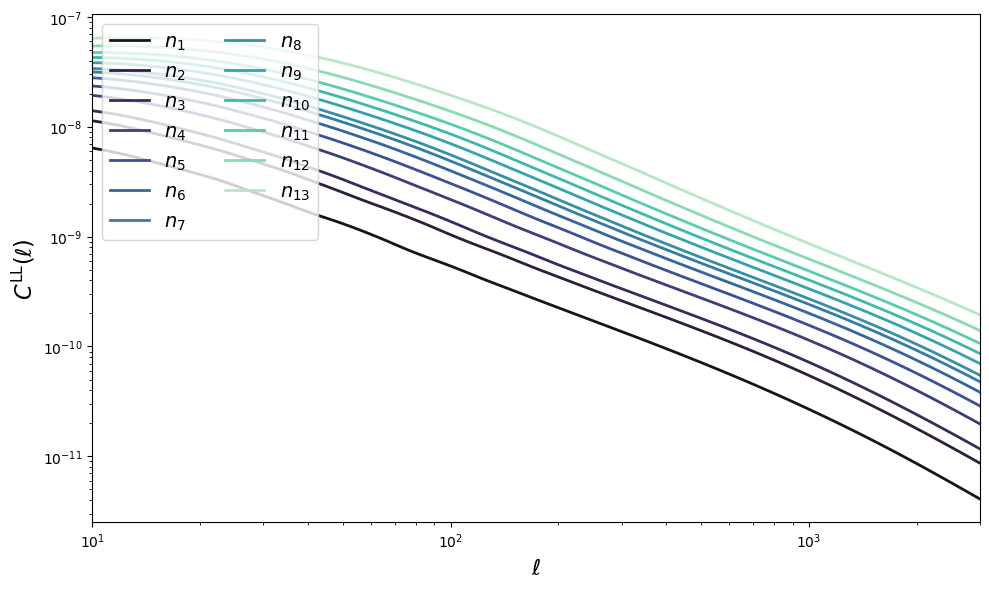

In [7]:
# Plot SHE-SHE C_ell's comparison #

fig, axes = plt.subplots(figsize=(10, 6))
colors = sns.color_palette("mako", 13)

#for i in range(0, 13):
#    ells = cells_gp['SHE', 'SHE', i+1, i+1].ell
#    axes[0].loglog(ells, ells*(2*ells+1)*cells_gp['SHE', 'SHE', i+1, i+1][0,0], label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])

for i in range(0, 13):
    ells = cells['SHE', 'SHE', i+1, i+1].ell
    axes.loglog(ells, cells['SHE', 'SHE', i+1, i+1][0,0], linewidth=2, color=colors[i], label = '$n_{{{}}}$'.format(i+1))
axes.set_xlabel(r'$\ell$', fontsize=16)
axes.set_ylabel(r'$C^{\rm LL}(\ell)$', fontsize=16);
#axes.set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{EE}(\ell)$'s", fontsize=14)
axes.set_xlim(np.min(ells), np.max(ells))
axes.legend(fontsize=14, loc='upper left', frameon=True, ncol=2)

#for i in range(0,13):
#    ells = cells['SHE', 'SHE', i+1, i+1].ell
#    cells_diff = 100*(np.asarray(cells['SHE', 'SHE', i+1, i+1][0,0]) - np.asarray(cells_gp['SHE', 'SHE', i+1, i+1][0,0])) / (np.asarray(cells['SHE', 'SHE', i+1, i+1][0,0]))
#    axes[1].semilogx(ells, cells_diff, label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])
#axes[1].set_xlabel(r'$\ell$')
#axes[1].set_ylabel(r'$\Delta C^{\rm EE}(\ell)/C^{\rm EE}(\ell)\cdot 100$')
#axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{EE}(\ell)$'s", fontsize=14)
#handles, labels = axes[0].get_legend_handles_labels()
#fig.legend(handles, labels, loc='center right')

# Adjust layout so legend fits nicely
#plt.subplots_adjust(right=0.85, wspace=0.25)
plt.tight_layout()
plt.savefig('/home/jipdebuck/plots/cells_WL.pdf', bbox_inches='tight')

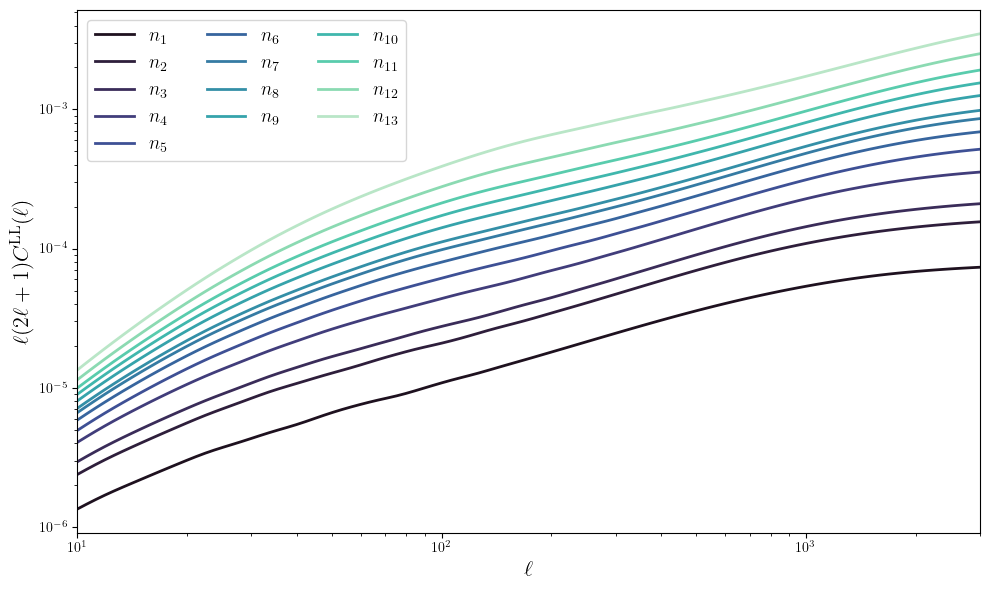

In [10]:
# Plot SHE-SHE C_ell's comparison #

fig, axes = plt.subplots(figsize=(10, 6))

#for i in range(0, 13):
#    ells = cells_gp['SHE', 'SHE', i+1, i+1].ell
#    axes[0].loglog(ells, ells*(2*ells+1)*cells_gp['SHE', 'SHE', i+1, i+1][0,0], label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])

for i in range(0, 13):
    ells = cells['SHE', 'SHE', i+1, i+1].ell
    axes.loglog(ells, ells*(2*ells+1)*cells['SHE', 'SHE', i+1, i+1][0,0], linewidth=2, color=colors[i], label = '$n_{{{}}}$'.format(i+1))
axes.set_xlabel(r'$\ell$', fontsize=16)
axes.set_ylabel(r'$\ell (2\ell +1)C^{\rm LL}(\ell)$', fontsize=16);
#axes.set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{EE}(\ell)$'s", fontsize=14)
axes.set_xlim(np.min(ells), np.max(ells))
axes.legend(fontsize=14, loc='upper left', frameon=True, ncol=3)

#for i in range(0,13):
#    ells = cells['SHE', 'SHE', i+1, i+1].ell
#    cells_diff = 100*(np.asarray(cells['SHE', 'SHE', i+1, i+1][0,0]) - np.asarray(cells_gp['SHE', 'SHE', i+1, i+1][0,0])) / (np.asarray(cells['SHE', 'SHE', i+1, i+1][0,0]))
#    axes[1].semilogx(ells, cells_diff, label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])
#axes[1].set_xlabel(r'$\ell$')
#axes[1].set_ylabel(r'$\Delta C^{\rm EE}(\ell)/C^{\rm EE}(\ell)\cdot 100$')
#axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{EE}(\ell)$'s", fontsize=14)
#handles, labels = axes[0].get_legend_handles_labels()
#fig.legend(handles, labels, loc='center right')

# Adjust layout so legend fits nicely
#plt.subplots_adjust(right=0.85, wspace=0.25)
plt.tight_layout()
plt.savefig('/home/jipdebuck/plots/cells_WL.png', bbox_inches='tight', dpi=600)

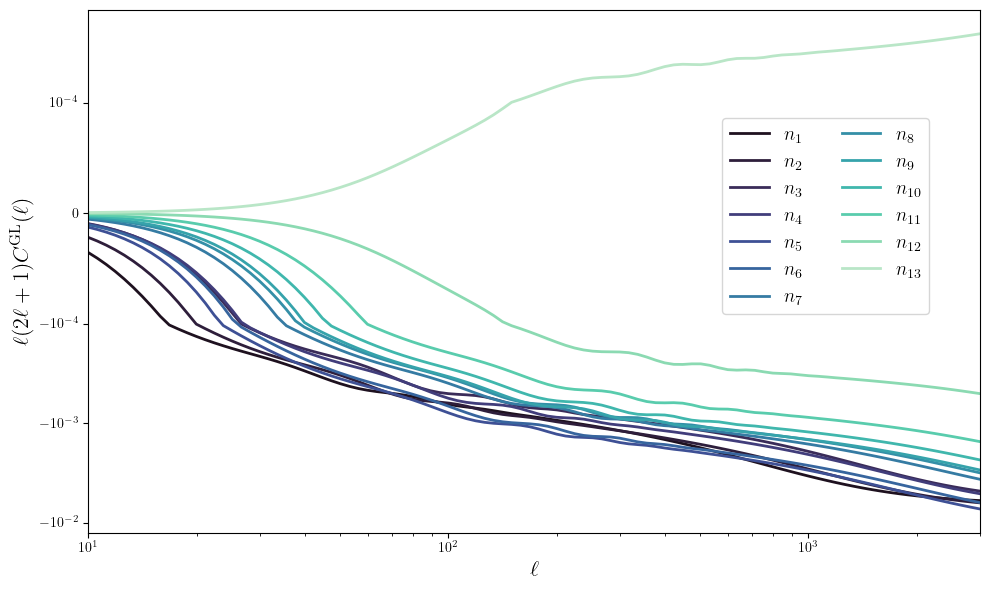

In [58]:
# Plot POS-SHE C_ell's comparison #

fig, axes = plt.subplots(figsize=(10, 6))

#for i in range(0, 13):
#    ells = cells_gp['POS', 'SHE', i+1, i+1].ell
#    axes[0].loglog(ells, ells*(2*ells+1)*cells_gp['POS', 'SHE', i+1, i+1][0], label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])

for i in range(0, 13):
    ells = cells['POS', 'SHE', i+1, i+1].ell
    axes.loglog(ells, ells*(2*ells+1)*cells['POS', 'SHE', i+1, i+1][0], linewidth=2, color=colors[i], label = '$n_{{{}}}$'.format(i+1))
axes.set_xlabel(r'$\ell$', fontsize=16)
axes.set_ylabel(r'$\ell (2\ell +1)C^{\rm GL}(\ell)$', fontsize=16);
#axes[0].set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{gE}(\ell)$'s", fontsize=14)
axes.legend(fontsize=14, bbox_to_anchor=(0.7, 0.4), ncol=2, frameon=True)
axes.set_yscale('symlog', linthresh=1e-4)
axes.set_xscale('log')
axes.set_xlim(np.min(ells), np.max(ells))

#for i in range(0,13):
#    ells = cells['POS', 'SHE', i+1, i+1].ell
#    cells_diff = (100*np.asarray(cells['POS', 'SHE', i+1, i+1][0]) - np.asarray(cells_gp['POS', 'SHE', i+1, i+1][0])) / (np.asarray(cells['POS', 'SHE', i+1, i+1][0]))
#    axes[1].semilogx(ells, cells_diff, label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])
#axes[1].set_xlabel(r'$\ell$')
#axes[1].set_ylabel(r'$\Delta C^{\rm gE}(\ell)/C^{\rm gE}(\ell)\cdot 100$')
#axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{gE}(\ell)$'s", fontsize=14)
#handles, labels = axes[0].get_legend_handles_labels()
#fig.legend(handles, labels, loc='center right')

# Adjust layout so legend fits nicely
#plt.subplots_adjust(right=0.85, wspace=0.25)
plt.tight_layout()
plt.savefig('/home/jipdebuck/plots/cells_GL.pdf', bbox_inches='tight')
plt.show()

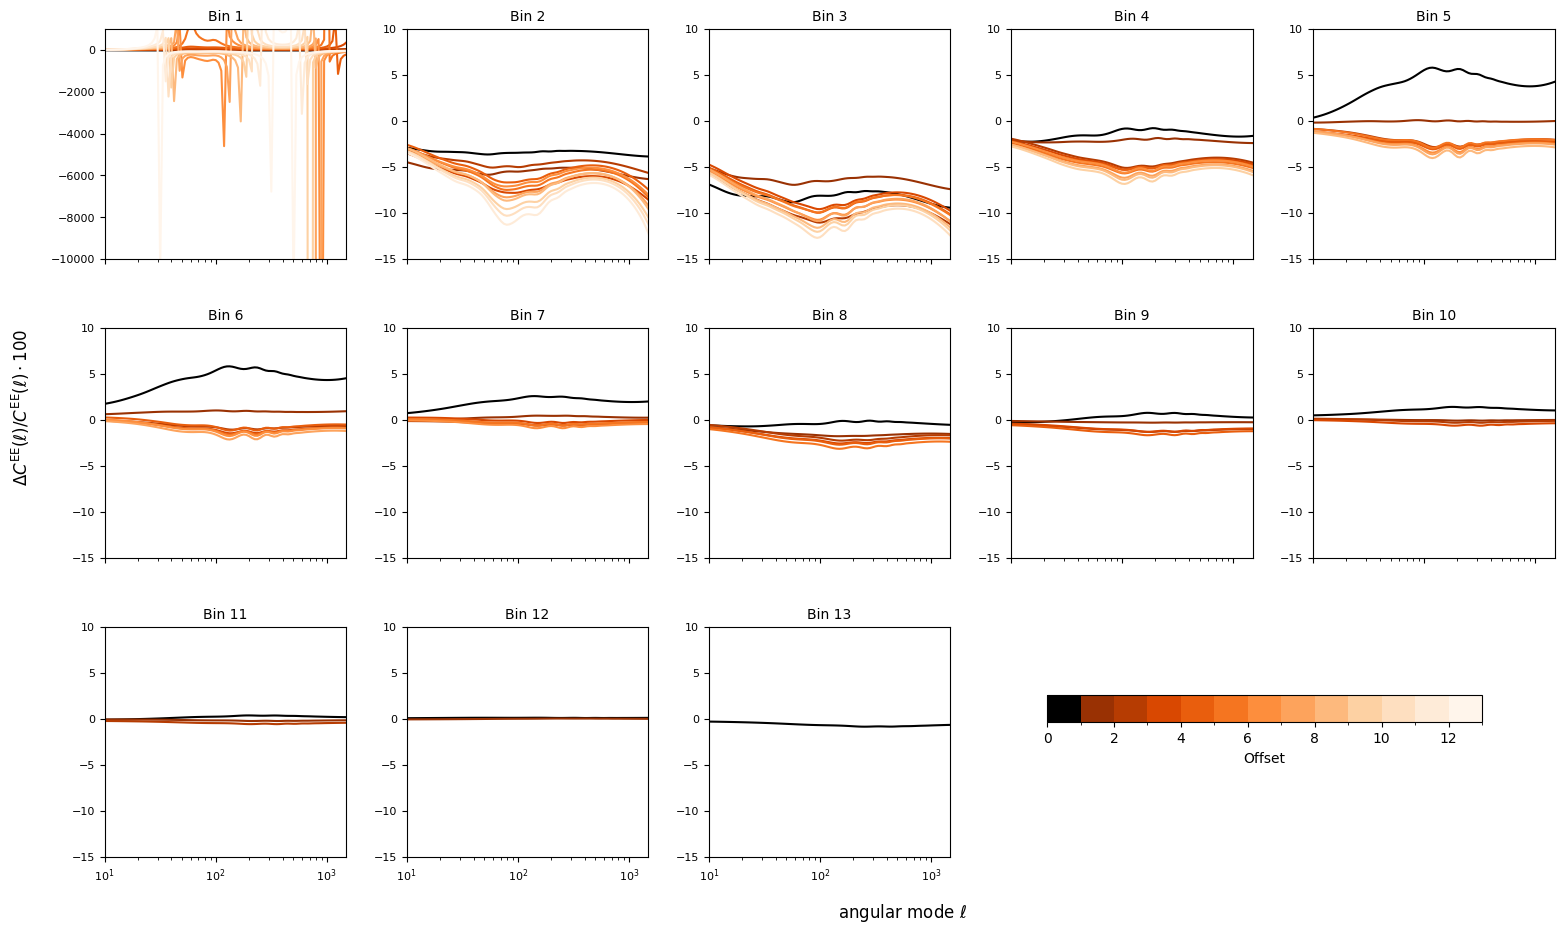

In [90]:
plot_cls_old_new(13, cells, cells_gp, "SHE", "SHE")

# Running tests with different nuisance parameters

### Testing the influence of the correlation length on the $C_{\ell}$'s 

Computing GP with correlation length: 0.005
Computing GP with correlation length: 0.02
Computing GP with correlation length: 0.05
Computing GP with correlation length: 0.1


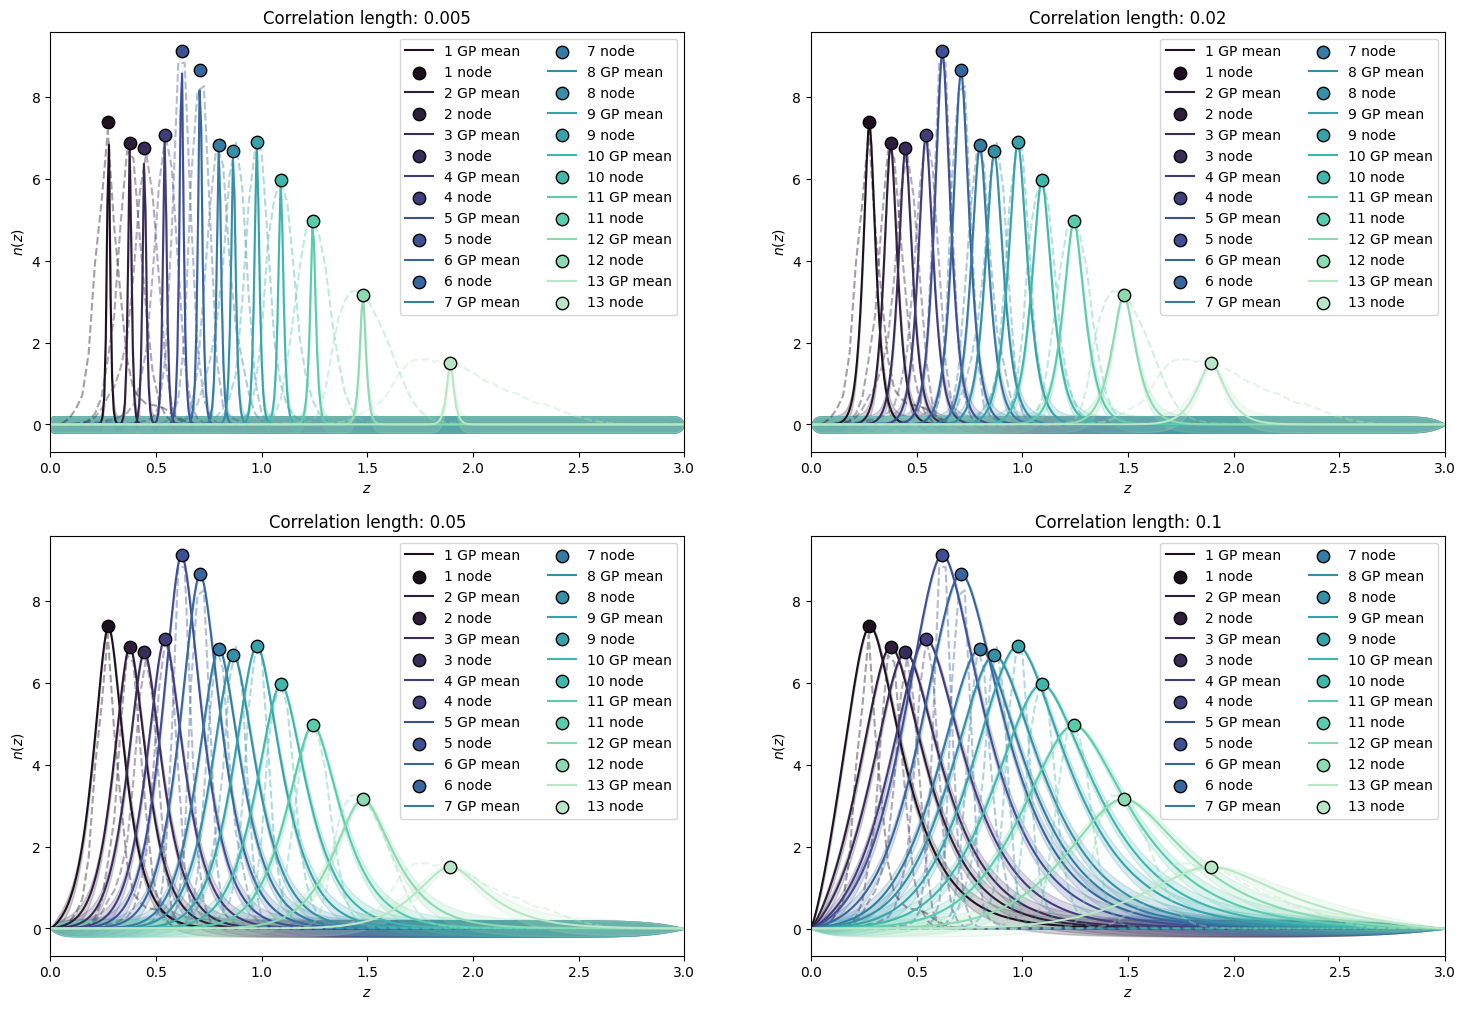

In [125]:
# First varying the correlation lengths in the Gaussian Process #

corr_lens = [0.005, 0.02, 0.05, 0.1]

# Perform GP reconstruction #
predictions_dict = {}
for corr_len in corr_lens:
    print(f"Computing GP with correlation length: {corr_len}")
    predictions_dict[f'Corr_len_{corr_len}'] = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

# Plot GP reconstruction results #
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()
palette = sns.color_palette("mako", 13)
for corr_len, ax in zip(corr_lens, axes):
    plot_nz_old_new(predictions_dict[f'Corr_len_{corr_len}'][1], z_pred, z_meds, n_meds, palette, ax, my_dndz_she_norm, zs, original=True, use_palette=True)
    ax.set_title(f'Correlation length: {corr_len}', fontsize=12)

In [ ]:
# Computing resampled n(z)'s and tracers with different correlation lengths #

resampled_pred = {}
for corr_len in corr_lens:
        resampled_pred[f'Corr_len_{corr_len}'] = resample_dndz_gp(predictions_dict[f'Corr_len_{corr_len}'][1], z_pred_res, zs)

tracers_she = {}
for corr_len in corr_lens:
    tracers_she[f'Corr_len_{corr_len}'] = ShearTracer(perturbations=perturbations, 
                                                dndz=resampled_pred[f'Corr_len_{corr_len}'],
                                                z = zs,
                                                nuisance_params={'AIA': 1.72, 'CIA': 0.0134, 'EtaIA':-0.41,
                                                  'multiplicative_bias_1': 0.001, 'multiplicative_bias_2': 0.001,
                                                  'multiplicative_bias_3': 0.001, 'multiplicative_bias_4': 0.001,
                                                  'multiplicative_bias_5': 0.001, 'multiplicative_bias_6': 0.001,
                                                  'multiplicative_bias_7': 0.001, 'multiplicative_bias_8': 0.001,
                                                  'multiplicative_bias_9': 0.001, 'multiplicative_bias_10': 0.001,
                                                  'multiplicative_bias_11': 0.001, 'multiplicative_bias_12': 0.001,
                                                  'multiplicative_bias_13': 0.001,
                                                  'dz_shear_1': 0.0001, 'dz_shear_2': 0.0001,
                                                    'dz_shear_3': 0.0001, 'dz_shear_4': 0.0001,
                                                    'dz_shear_5': 0.0001, 'dz_shear_6': 0.0001,
                                                    'dz_shear_7': 0.0001, 'dz_shear_8': 0.0001,
                                                    'dz_shear_9': 0.0001, 'dz_shear_10': 0.0001,
                                                    'dz_shear_11': 0.0001, 'dz_shear_12': 0.0001,
                                                    'dz_shear_13': 0.0001})

In [160]:
# Computing shear-shear angular two-point statistics #

nl = 100
ells = np.logspace(1., np.log10(3000), nl)

twopoint_dict = {}
for corr_len in corr_lens:
    twopoint_dict[f'Corr_len_{corr_len}'] = AngularTwoPoint(tracers_she[f'Corr_len_{corr_len}'], tracers_she[f'Corr_len_{corr_len}'])

#twopoint_0.005 = twopoint_dict['Corr_len_0.005']

cells_dict = {}
for corr_len in corr_lens:
    cells_dict[f'Corr_len_{corr_len}'] ={**twopoint_dict[f'Corr_len_{corr_len}'].get_Cl(ells, 0, perturbations.k)}


<>:13: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1119/1739619627.py:13: SyntaxWarning: invalid escape sequence '\e'
  axes.set_title("$C^{EE}(\ell)$'s from n(z)'s with different correlation lengths", fontsize=14)


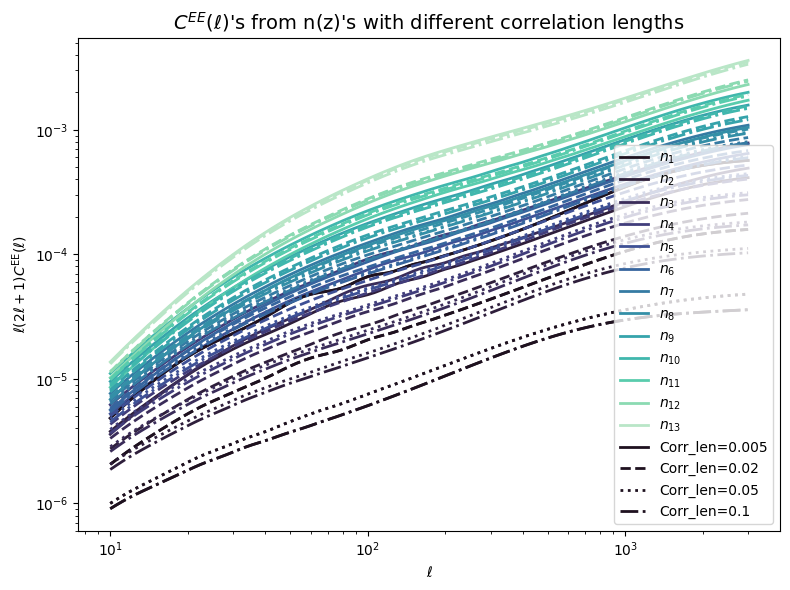

In [162]:
# Plotting all shear-shear C_ell's in one figure # 

fig, axes = plt.subplots(1, 1, figsize=(8, 6))
linestyles = ['-', '--', ':', '-.'] 
for corr_len, color, linestyle in zip(corr_lens, colors, linestyles):
    cell_gp = cells_dict[f'Corr_len_{corr_len}']
    for i in range(0, 13):
        ells = cells['SHE', 'SHE', i+1, i+1].ell
        axes.loglog(ells, ells*(2*ells+1)*cell_gp['SHE', 'SHE', i+1, i+1][0,0], linestyle=linestyle, label = '$n_{{{}}}$'.format(i+1) if corr_len == corr_lens[0] else None, linewidth=2, color=palette[i])
    axes.loglog(ells, ells*(2*ells+1)*cell_gp['SHE', 'SHE', 1,1][0,0], linewidth=2, linestyle=linestyle, label=f'Corr_len={corr_len}', color=palette[0])
    axes.set_xlabel(r'$\ell$')
    axes.set_ylabel(r'$\ell (2\ell +1)C^{\rm EE}(\ell)$');
    axes.set_title("$C^{EE}(\ell)$'s from n(z)'s with different correlation lengths", fontsize=14)
    axes.legend(fontsize=10, loc='lower right', frameon=True)

#    for i in range(0,13):
#        ells = cells['SHE', 'SHE', i+1, i+1].ell
#        cells_diff = 100*(np.asarray(cells['SHE', 'SHE', i+1, i+1][0,0]) - np.asarray(cells_gp['SHE', 'SHE', i+1, i+1][0,0])) / (np.asarray(cells['SHE', 'SHE', i+1, i+1][0,0]))
#        axes[1].semilogx(ells, cells_diff, label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])
#    axes[1].set_xlabel(r'$\ell$')
#    axes[1].set_ylabel(r'$\Delta C^{\rm EE}(\ell)/C^{\rm EE}(\ell)\cdot 100$')
#    axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{EE}(\ell)$'s", fontsize=14)
#handles, labels = axes[0].get_legend_handles_labels()
#fig.legend(handles, labels, loc='center right')

# Adjust layout so legend fits nicely
plt.subplots_adjust(right=0.85, wspace=0.25)
plt.tight_layout()
plt.show()

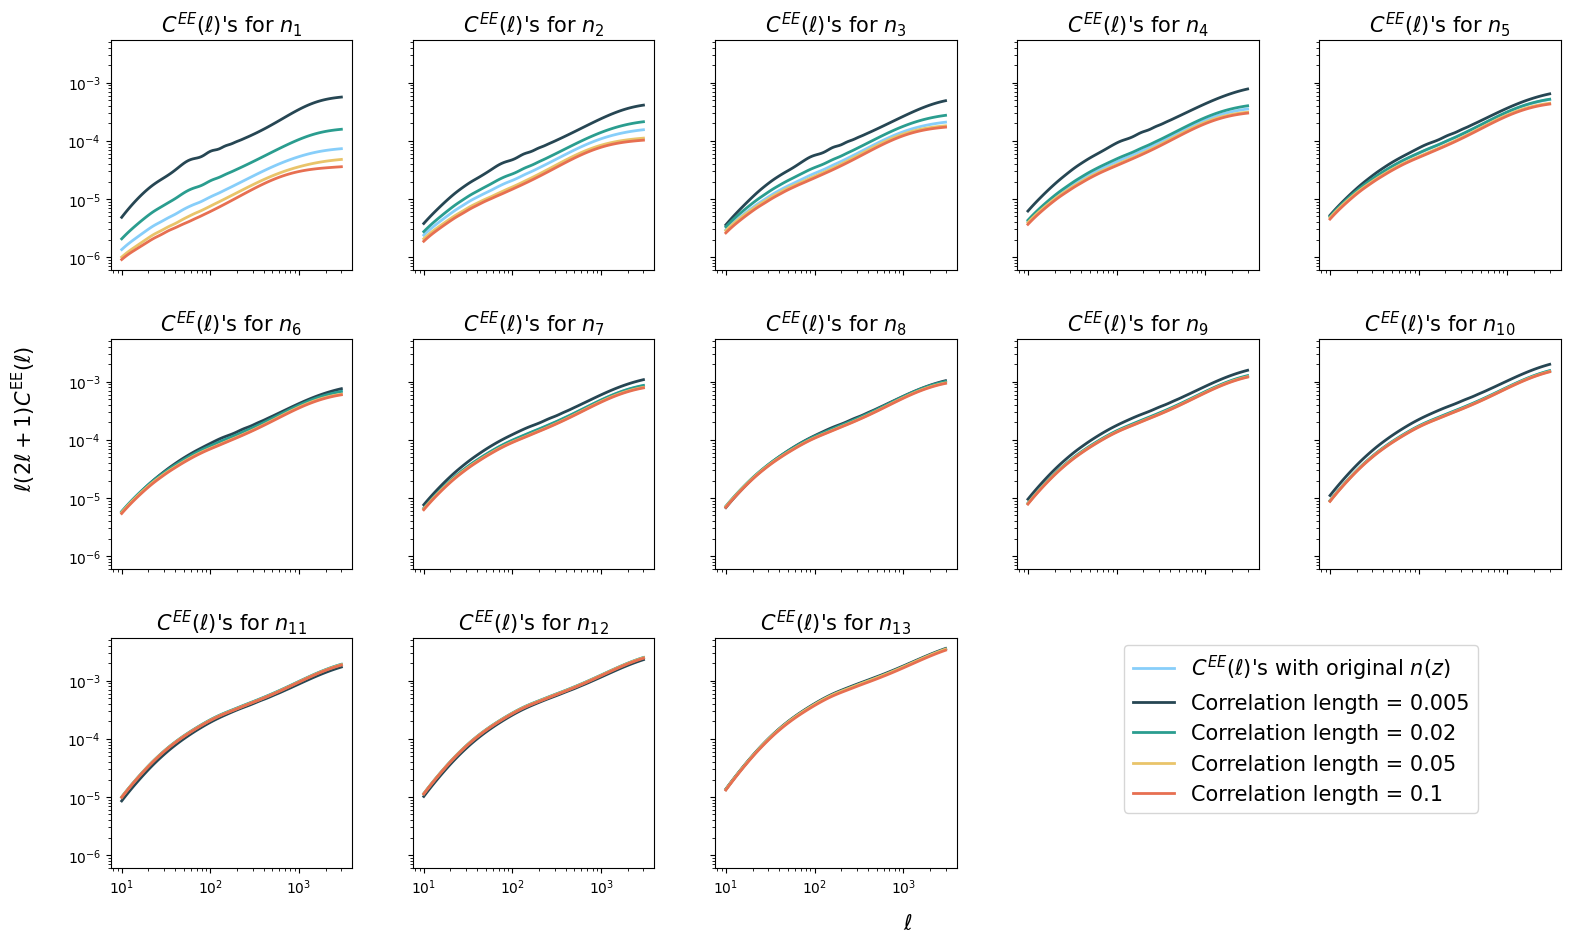

In [ ]:
# Plotting shear-shear C_ells in a separate figure per bin #

colors = ['#264653', '#2A9D8F', '#E9C46A', '#E76F51']
fig, axes = plt.subplots(3, 5, figsize=(14.5,9), sharey=True, sharex=True)
axes = axes.flatten()
axes_to_remove = [axes[13], axes[14]]
for ax in axes_to_remove:
    ax.remove()

for i in range(0,13):
    ells = cells['SHE', 'SHE', i+1, i+1].ell
    axes[i].loglog(ells, ells*(2*ells+1)*cells['SHE', 'SHE', i+1, i+1][0,0], label=f"$C^{{EE}}(\\ell)$'s with original $n(z)$", linewidth=2, color='lightskyblue')

for corr_len, color in zip(corr_lens, colors):
    cell_gp = cells_dict[f'Corr_len_{corr_len}']
    for i in range(0, 13):
        ells = cells['SHE', 'SHE', i+1, i+1].ell
        axes[i].loglog(ells, ells*(2*ells+1)*cell_gp['SHE', 'SHE', i+1, i+1][0,0], label = f'Correlation length = {corr_len}', linewidth=2, color=color)
        axes[i].set_title(f"$C^{{EE}}(\\ell)$'s for $n_{{{i+1}}}$", fontsize=15)
    fig.supxlabel(r'$\ell$', y=-0.05, va="top", fontsize=15)
    fig.supylabel(r'$\ell (2\ell +1)C^{\rm EE}(\ell)$', x=-0.1, ha="right", fontsize=15)
    fig.subplots_adjust(
    left=-0.05,    # space on the left for y-axis
    right=0.95,   # space on the right
    top=0.92,     # space at the top
    bottom=0,  # space at the bottom for x-axis + colorbar
    hspace=0.3,   # vertical spacing between subplots
    wspace=0.25   # horizontal spacing between subplots
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower right', fontsize=15, bbox_to_anchor=(0.9, 0.05), frameon=True)



### Testing the influence of the training nodes x-positions on the $C_{\ell}$'s 

dict_keys(['Shift_-0.2', 'Shift_-0.1', 'Shift_-0.01', 'Shift_0.0', 'Shift_0.01', 'Shift_0.1', 'Shift_0.2'])


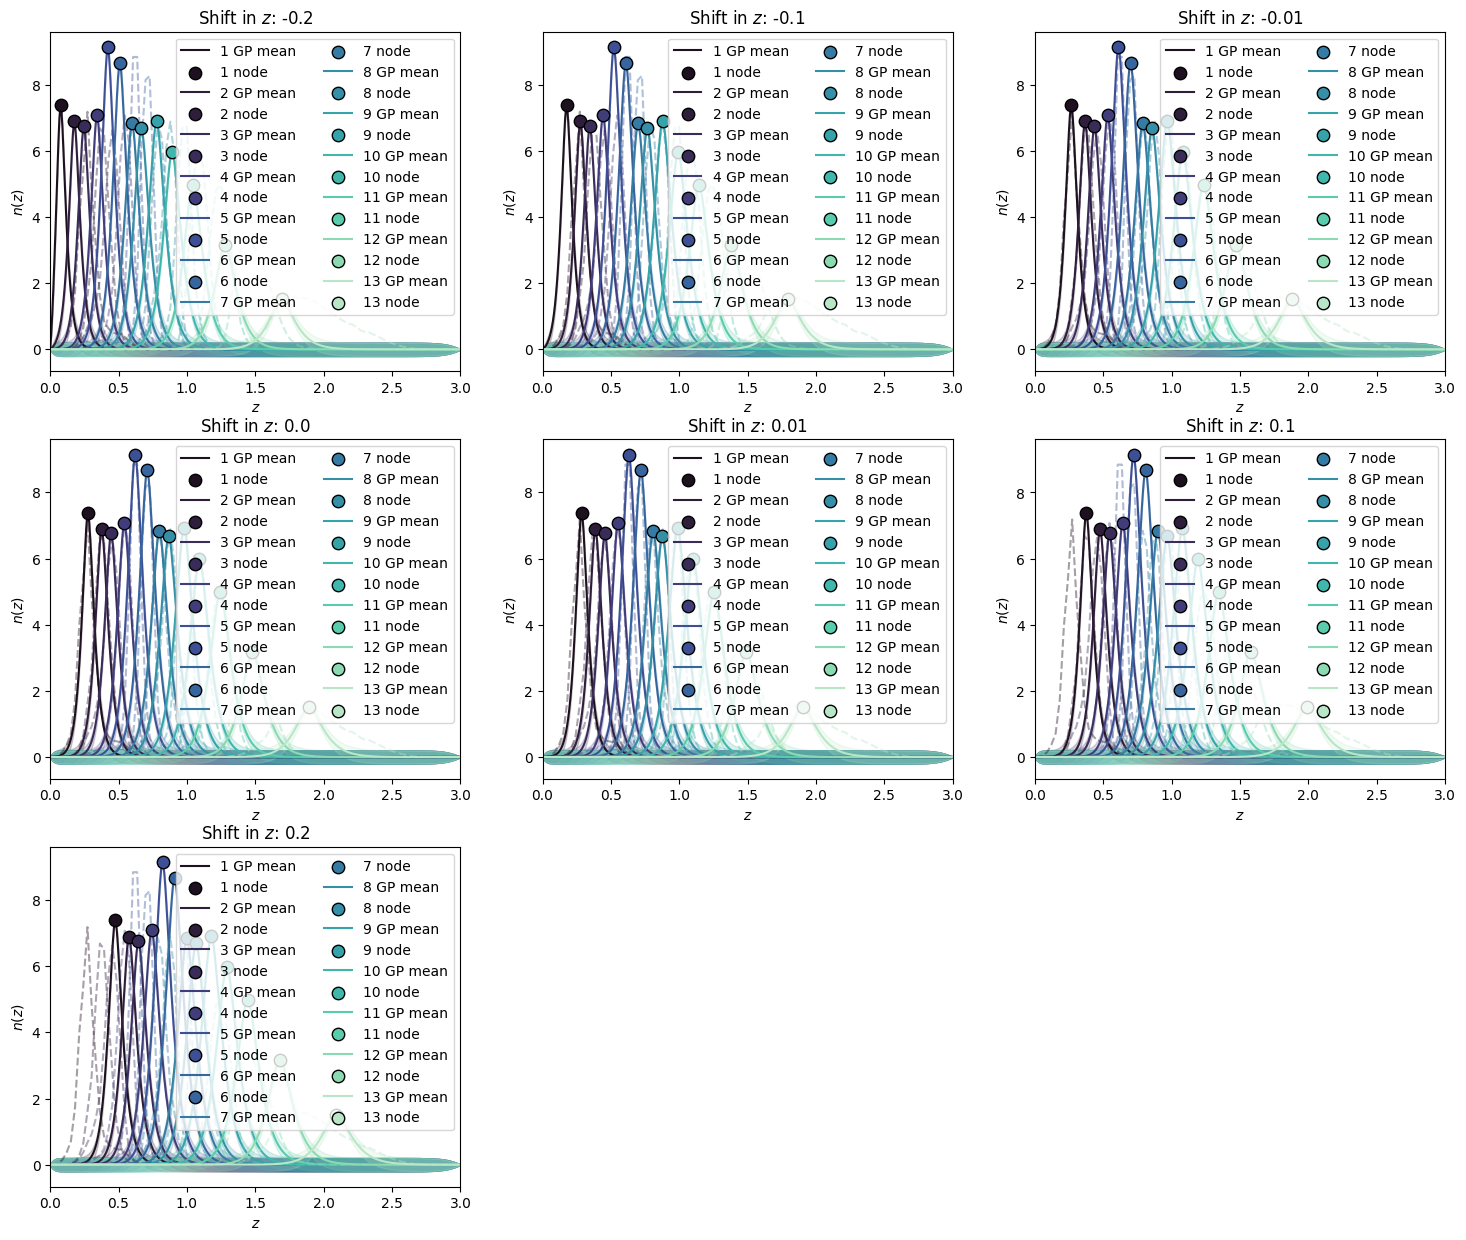

In [179]:
# Now shifting the horizontal positions of the training nodes #

# Perform GP reconstruction #
corr_len = 0.03
delta_zs = [-0.2, -0.1, -0.01, 0.0, 0.01, 0.1, 0.2]
predictions_shift = {}
for delta_z in delta_zs:
    delta_z = [delta_z]*13
    predictions_shift[f'Shift_{delta_z[0]}'] = build_gp_nz(n_meds, np.array(z_meds)+np.array(delta_z), corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

print(predictions_shift.keys())
# Plot GP reconstruction results #
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()
axes_to_remove = [axes[7], axes[8]]
for ax in axes_to_remove:
    ax.remove()

palette = sns.color_palette("mako", 13)
for delta_z, ax in zip(delta_zs, axes):
    delta_z = [delta_z]*13
    plot_nz_old_new(predictions_shift[f'Shift_{delta_z[0]}'][1], z_pred, np.array(z_meds)+np.array(delta_z), n_meds, palette, ax, my_dndz_she_norm, zs, original=True, use_palette=True)
    ax.set_title(f'Shift in $z$: {delta_z[0]}', fontsize=12)


In [180]:
# Computing resampled n(z)'s and tracers with different shifts in z #

resampled_pred_shift = {}
print(delta_zs)
for delta_z in delta_zs:
        resampled_pred_shift[f'Shift_{delta_z}'] = resample_dndz_gp(predictions_shift[f'Shift_{delta_z}'][1], z_pred_res, zs)



[-0.2, -0.1, -0.01, 0.0, 0.01, 0.1, 0.2]


In [181]:
# Computing shear tracers #

tracers_she_shift = {}
for delta_z in delta_zs:
    tracers_she_shift[f'Shift_{delta_z}'] = ShearTracer(perturbations=perturbations, 
                                                dndz=resampled_pred_shift[f'Shift_{delta_z}'],
                                                z = zs,
                                                nuisance_params={'AIA': 1.72, 'CIA': 0.0134, 'EtaIA':-0.41,
                                                  'multiplicative_bias_1': 0.001, 'multiplicative_bias_2': 0.001,
                                                  'multiplicative_bias_3': 0.001, 'multiplicative_bias_4': 0.001,
                                                  'multiplicative_bias_5': 0.001, 'multiplicative_bias_6': 0.001,
                                                  'multiplicative_bias_7': 0.001, 'multiplicative_bias_8': 0.001,
                                                  'multiplicative_bias_9': 0.001, 'multiplicative_bias_10': 0.001,
                                                  'multiplicative_bias_11': 0.001, 'multiplicative_bias_12': 0.001,
                                                  'multiplicative_bias_13': 0.001,
                                                  'dz_shear_1': 0.0001, 'dz_shear_2': 0.0001,
                                                    'dz_shear_3': 0.0001, 'dz_shear_4': 0.0001,
                                                    'dz_shear_5': 0.0001, 'dz_shear_6': 0.0001,
                                                    'dz_shear_7': 0.0001, 'dz_shear_8': 0.0001,
                                                    'dz_shear_9': 0.0001, 'dz_shear_10': 0.0001,
                                                    'dz_shear_11': 0.0001, 'dz_shear_12': 0.0001,
                                                    'dz_shear_13': 0.0001})


In [182]:
# Computing shear-shear angular two-point statistics #

twopoint_dict_shift = {}
for delta_z in delta_zs:
    twopoint_dict_shift[f'Shift_{delta_z}'] = AngularTwoPoint(tracers_she_shift[f'Shift_{delta_z}'], tracers_she_shift[f'Shift_{delta_z}'])

cells_dict_shift = {}
for delta_z in delta_zs:
    cells_dict_shift[f'Shift_{delta_z}'] ={**twopoint_dict_shift[f'Shift_{delta_z}'].get_Cl(ells, 0, perturbations.k)}

<>:18: SyntaxWarning: invalid escape sequence '\D'
<>:18: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_1119/3035946285.py:18: SyntaxWarning: invalid escape sequence '\D'
  axes[i].loglog(ells, ells*(2*ells+1)*cell_gp_shift['SHE', 'SHE', i+1, i+1][0,0], label = f'$\Delta z$ = {delta_z}', linewidth=2, color=color)


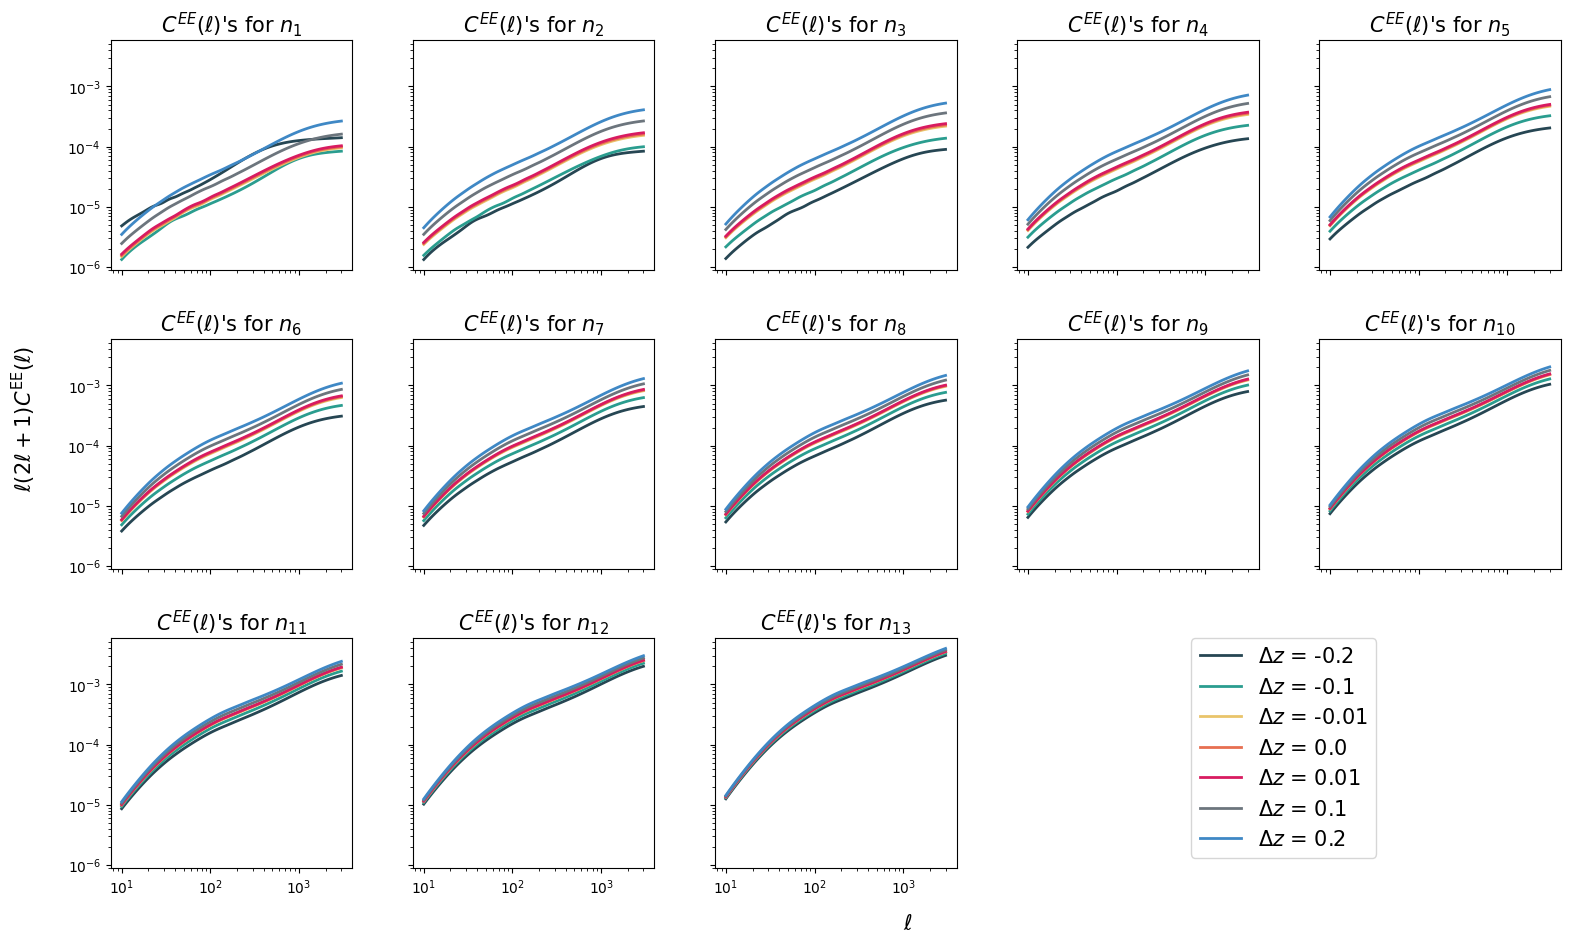

In [192]:
# Plotting shear-shear C_ells in a separate figure per bin #

colors = ['#264653', '#2A9D8F', '#E9C46A', '#E76F51', '#D81B60', '#6C757D', '#3F88C5']
fig, axes = plt.subplots(3, 5, figsize=(14.5,9), sharey=True, sharex=True)
axes = axes.flatten()
axes_to_remove = [axes[13], axes[14]]
for ax in axes_to_remove:
    ax.remove()

#for i in range(0,13):
#    ells = cells['SHE', 'SHE', i+1, i+1].ell
#    axes[i].loglog(ells, ells*(2*ells+1)*cells['SHE', 'SHE', i+1, i+1][0,0], label=f"$C^{{EE}}(\\ell)$'s with original $n(z)$", linewidth=2, color='lightskyblue')

for delta_z, color in zip(delta_zs, colors):
    cell_gp_shift = cells_dict_shift[f'Shift_{delta_z}']
    for i in range(0, 13):
        ells = cells['SHE', 'SHE', i+1, i+1].ell
        axes[i].loglog(ells, ells*(2*ells+1)*cell_gp_shift['SHE', 'SHE', i+1, i+1][0,0], label = f'$\Delta z$ = {delta_z}', linewidth=2, color=color)
        axes[i].set_title(f"$C^{{EE}}(\\ell)$'s for $n_{{{i+1}}}$", fontsize=15)
    fig.supxlabel(r'$\ell$', y=-0.05, va="top", fontsize=15)
    fig.supylabel(r'$\ell (2\ell +1)C^{\rm EE}(\ell)$', x=-0.1, ha="right", fontsize=15)
    fig.subplots_adjust(
    left=-0.05,    # space on the left for y-axis
    right=0.95,   # space on the right
    top=0.92,     # space at the top
    bottom=0,  # space at the bottom for x-axis + colorbar
    hspace=0.3,   # vertical spacing between subplots
    wspace=0.25   # horizontal spacing between subplots
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower right', fontsize=15, bbox_to_anchor=(0.83, 0.0), frameon=True)

